In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import os
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [4]:
df = pd.read_csv('real_estate_data.csv')

In [5]:
print("Первые 5 строк:")
display(df.head())
print("Последние 5 строк:")
display(df.tail())
print("Случайная строка:")
display(df.sample())

Первые 5 строк:


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3500.0,TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY
3,4,Konut,Rezidans,9/10/18,10/10/18,1,30,3,20 ve üzeri,20 ve üzeri,6+1,450.0,İstanbul/Beşiktaş/Levent,NaN,Fancoil,32500000.0,TRY
4,5,Konut,Rezidans,12/10/18,1/9/19,1,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,1450000.0,TRY


Последние 5 строк:


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
403482,403483,Konut,Daire,9/18/18,NaN,2,162,NaN,NaN,NaN,+,NaN,İstanbul/Sultanbeyli/Adil,NaN,NaN,1500.0,TRY
403483,403484,Konut,Daire,10/11/18,NaN,1,139,NaN,NaN,NaN,2+1,NaN,Sakarya/Adapazarı/Cumhuriyet,NaN,NaN,120000.0,TRY
403484,403485,Konut,Daire,11/22/18,NaN,1,97,NaN,NaN,NaN,1+1,NaN,Antalya/Alanya/Saray,NaN,NaN,48000.0,EUR
403485,403486,Konut,Daire,2/21/19,NaN,2,6,NaN,NaN,NaN,2+1,2.0,Aydın/Kuşadası/Türkmen,NaN,NaN,900.0,TRY
403486,403487,Konut,Daire,1/15/19,1/18/19,1,3,NaN,NaN,NaN,3+1,140.0,Kayseri/Melikgazi/Alpaslan,NaN,NaN,210000.0,TRY


Случайная строка:


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
192725,192726,Konut,Daire,1/9/19,NaN,1,49,2,3,3,2+1,NaN,İstanbul/Bahçelievler/Çobançeşme,NaN,Kombi (Doğalgaz),320000.0,TRY


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  str    
 2   sub_type           403487 non-null  str    
 3   start_date         403487 non-null  str    
 4   end_date           266298 non-null  str    
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  str    
 8   total_floor_count  375466 non-null  str    
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  str    
 11  size               257481 non-null  float64
 12  address            403487 non-null  str    
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  str    
 15  price              402772 non-null  float64
 16  price_currenc

## Описание источника данных

#### id - идентификатор объявления;
#### type -тип недвижимости;
#### sub_type - подтип(квартира, дом и т.д.);
#### start_date - дата публикации объявления
#### end_date - дата окончания публикации объявления;
#### listing_type - тип листинга;
#### tom - время на рынке;
#### building_age - возраст здания;
#### total_floor_count - количество этажей;
#### floor_no - этаж;
#### room_count - количество комнат;
#### size - площадь;
#### address - адрес;
#### furnished - наличие мебели;
#### heating_type - тип отопления;
#### price - цена;
#### price_currency - валюта.

## Статистика числовых признаков

In [17]:
num = df.select_dtypes(include='number')
stats = num.describe().T
stats['median'] = num.median()
stats = stats[['min', 'max', 'mean', '25%', '50%', '75%', 'median', 'std']]
display(stats)

,min,max,mean,25%,50%,75%,median,std
id,1.0,4.034870e+05,201744.000000,100872.5,201744.0,302615.5,201744.0,1.164768e+05
listing_type,1.0,3.000000e+00,1.294235,1.0,1.0,2.0,1.0,4.677333e-01
tom,0.0,1.800000e+02,57.022739,29.0,40.0,90.0,40.0,4.435893e+01
size,1.0,9.482350e+05,279.349094,85.0,110.0,140.0,110.0,9.429195e+03
furnished,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,-250.0,2.000000e+09,354641.661933,2500.0,199000.0,342000.0,199000.0,4.809503e+06


In [21]:
cat = df.select_dtypes(include='str')
for col in cat.columns:
    print("Частота категорий:")
    display(cat[col].value_counts(dropna=False))

Частота категорий:


type
Konut    403487
Name: count, dtype: int64

Частота категорий:


sub_type
Daire                  354549
Villa                   21324
Müstakil Ev              9563
Rezidans                 7716
Yazlık                   5929
Komple Bina              2607
Prefabrik Ev              679
Çiftlik Evi               528
Köşk / Konak / Yalı       301
Yalı Dairesi              187
Kooperatif                 70
Loft                       34
Name: count, dtype: int64

Частота категорий:


start_date
10/11/18    4064
9/26/18     3892
10/17/18    3846
10/5/18     3832
10/2/18     3630
            ... 
12/30/18     721
2/17/19      712
1/27/19      672
1/1/19       635
2/3/19       630
Name: count, Length: 181, dtype: int64

Частота категорий:


end_date
NaN         137189
12/19/18      3048
1/18/19       2866
2/20/19       2831
2/9/19        2785
             ...  
9/9/18         120
9/3/18         109
9/1/18          54
8/31/18         52
9/2/18          38
Name: count, Length: 182, dtype: int64

Частота категорий:


building_age
0              140174
6-10 arası      50495
11-15 arası     32309
16-20 arası     31333
NaN             27390
1               20355
4               19032
21-25 arası     18438
2               17466
3               15651
5               13589
26-30 arası     10581
31-35 arası      4268
36-40 arası      1347
40 ve üzeri      1059
Name: count, dtype: int64

Частота категорий:


total_floor_count
4              83082
3              77956
5              70104
10-20 arası    36512
NaN            28021
2              27742
6              23348
10             12558
7              12284
8              11207
9               9029
20 ve üzeri     6679
1               4965
Name: count, dtype: int64

Частота категорий:


floor_no
2               65864
3               52690
1               46756
NaN             35296
4               34465
Yüksek Giriş    24045
5               21193
Müstakil        21165
Bahçe katı      19065
Giriş Katı      10431
6                9747
7                7698
8                6099
Kot 1            5036
Kot 2            4987
9                4855
10               3863
Kot 3            3793
Çatı Katı        3566
Zemin Kat        3441
Komple           2958
11               2894
12               2309
Kot 4            2269
13               1702
20 ve üzeri      1563
14               1328
15                911
En Üst Kat        894
Bodrum Kat        815
16                600
17                373
18                334
Teras Kat         293
19                177
Asma Kat           12
Name: count, dtype: int64

Частота категорий:


room_count
3+1     157363
2+1     138677
1+1      39134
4+1      37472
5+1       8219
4+2       4540
5+2       2926
+         2898
3+2       2673
1+0       2612
6+1       2001
6+2       1517
2+2        836
7+1        523
7+2        428
10+0       313
8+1        218
8+2        189
6+3        167
5+3        139
4+3        133
7+3         86
9+1         71
9+3         65
9+2         61
8+3         55
8+4         38
10+1        35
10+2        30
9+5         27
9+4         26
10+3         9
10+5         2
0+0          1
10+4         1
11+3         1
15+5         1
Name: count, dtype: int64

Частота категорий:


address
Balıkesir/Edremit/Akçay                   5611
Aydın/Didim/Efeler                        4203
İstanbul/Beylikdüzü/Cumhuriyet            3283
İstanbul/Bahçelievler/Siyavuşpaşa         2139
Aydın/Didim/Altınkum                      2085
                                          ... 
Ağrı/Merkez/Ballıbostan Köyü                 1
Edirne/Lalapaşa/Süleymandanişment Köyü       1
Antalya/Korkuteli/Ulucak                     1
Kastamonu/Merkez/Kırkçeşme                   1
İzmir/Tire/Gökçen                            1
Name: count, Length: 7842, dtype: int64

Частота категорий:


heating_type
Kombi (Doğalgaz)                   204150
Klima                               68197
Merkezi Sistem (Isı Payı Ölçer)     30595
NaN                                 27970
Merkezi Sistem                      22855
Kalorifer (Doğalgaz)                10928
Soba (Kömür)                         8450
Yerden Isıtma                        6958
Yok                                  6098
Kat Kaloriferi                       5655
Kombi (Elektrikli)                   3449
Soba (Doğalgaz)                      2602
Güneş Enerjisi                       1754
Kalorifer (Kömür)                    1503
Jeotermal                            1418
Fancoil                               495
Kalorifer (Akaryakıt)                 410
Name: count, dtype: int64

Частота категорий:


price_currency
TRY    400677
EUR       922
NaN       715
GBP       621
USD       552
Name: count, dtype: int64

### sub_type — самая частая категория

In [24]:
cat = df.select_dtypes(include='str')

print("Количество уникальных значений:")
display(cat.nunique())

Количество уникальных значений:


type                    1
sub_type               12
start_date            181
end_date              181
building_age           14
total_floor_count      12
floor_no               35
room_count             37
address              7842
heating_type           16
price_currency          4
dtype: int64

## Гистограмма цены и точность асиметрии

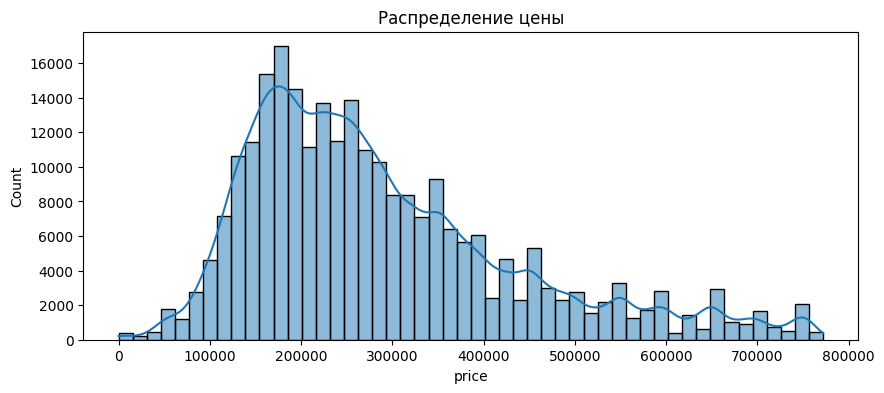

Skew после обрезки: 1.059725404271949


In [28]:
Q1 = d['price'].quantile(0.25)
Q3 = d['price'].quantile(0.75)
IQR = Q3 - Q1

d = d[(d['price'] >= Q1 - 1.5 * IQR) & (d['price'] <= Q3 + 1.5 * IQR)]

plt.figure(figsize=(10, 4))
sns.histplot(d['price'], bins=50, kde=True)
plt.title('Распределение цены в TRY')
plt.show()

print("Skew после обрезки:", d['price'].skew())

## Визуальный анализ

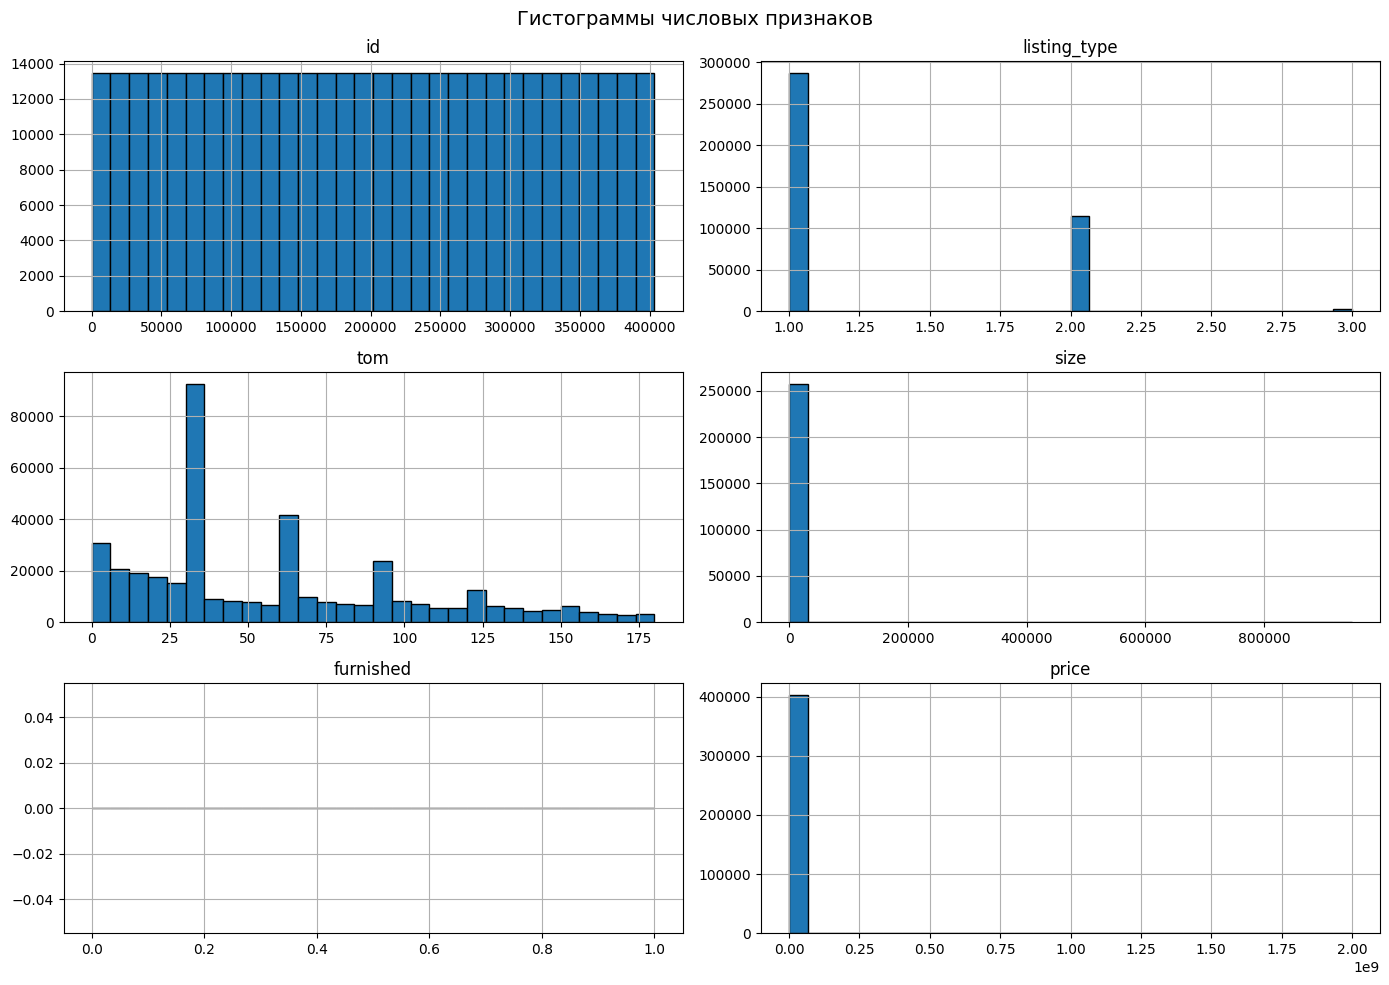

In [30]:
num = df.select_dtypes(include='number')

num.hist(figsize=(14, 10), bins=30, edgecolor='black')
plt.suptitle('Гистограммы числовых признаков', fontsize=14)
plt.tight_layout()
plt.show()

## Диаграммы рассеяния

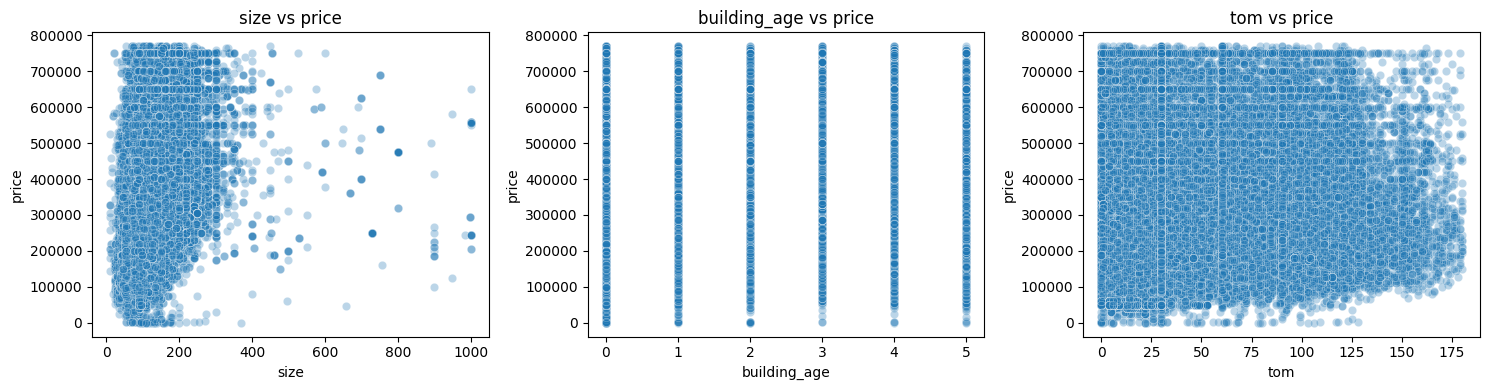

In [66]:
d['size'] = pd.to_numeric(d['size'], errors='coerce')
d['building_age'] = pd.to_numeric(d['building_age'], errors='coerce')
d = d[(d['size'] >= 10) & (d['size'] <= 1000)]
d = d[(d['building_age'] >= 0) & (d['building_age'] <= 100)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['size', 'building_age', 'tom']):
    sns.scatterplot(data=d, x=col, y='price', alpha=0.3, ax=ax)
    ax.set_title(f'{col} vs price')

plt.tight_layout()
plt.show()

## Boxplot

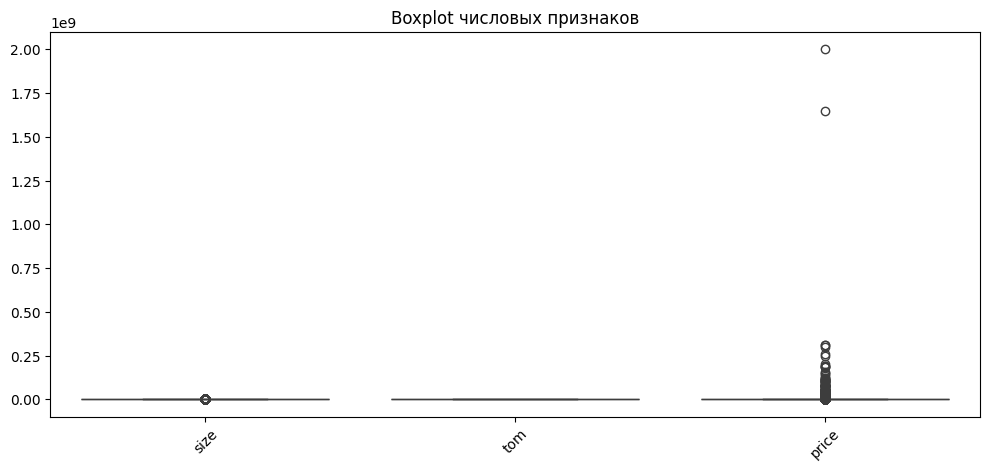

In [37]:
d = df[(df['listing_type'] == 1) & (df['price_currency'] == 'TRY')].copy()

cols = ['size', 'building_age', 'tom', 'price']

plt.figure(figsize=(12, 5))
sns.boxplot(data=d[cols])
plt.title('Boxplot числовых признаков')
plt.xticks(rotation=45)
plt.show()

## Тепловая карта 

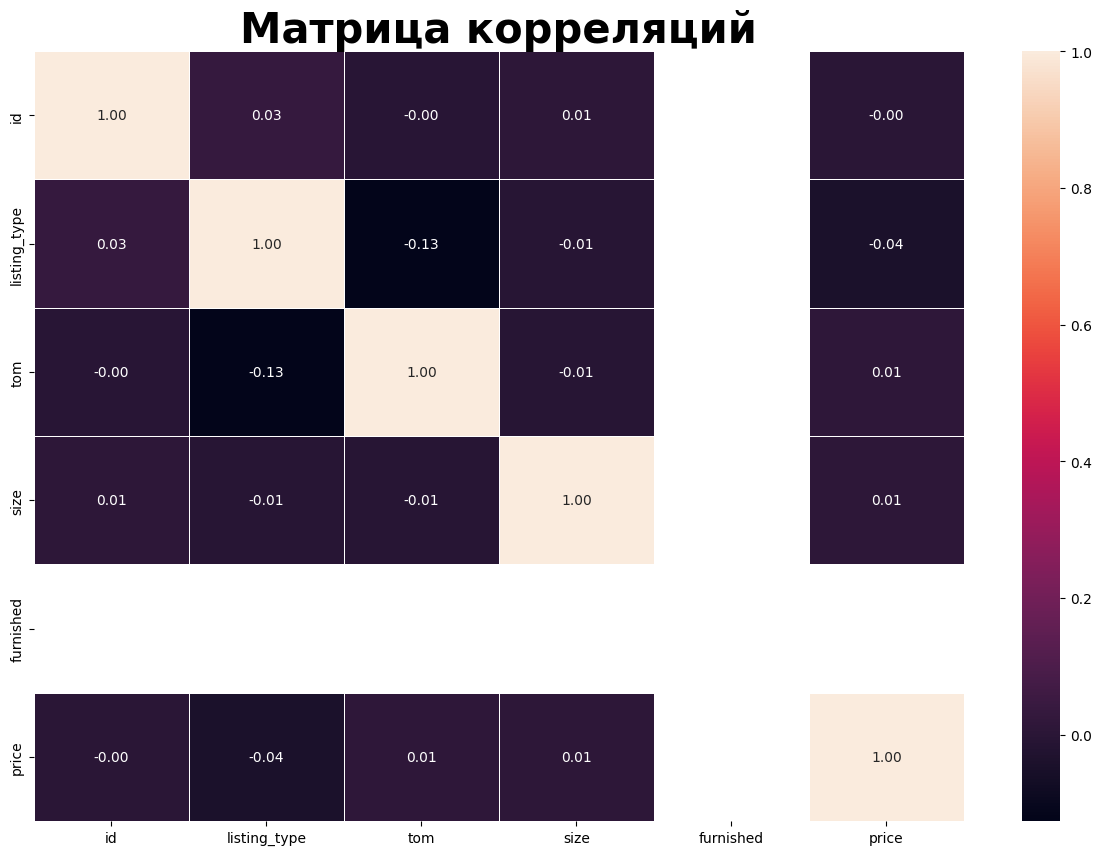

In [39]:
corr = df.corr(numeric_only=True)

fig = plt.subplots(figsize=(15, 10))
sns.heatmap(corr, 
            annot=True, 
            fmt='.2f',
            linewidths=0.5)

plt.title('Матрица корреляций', fontsize=30, fontweight='bold')
plt.show()

## Анализ категориальных признаков

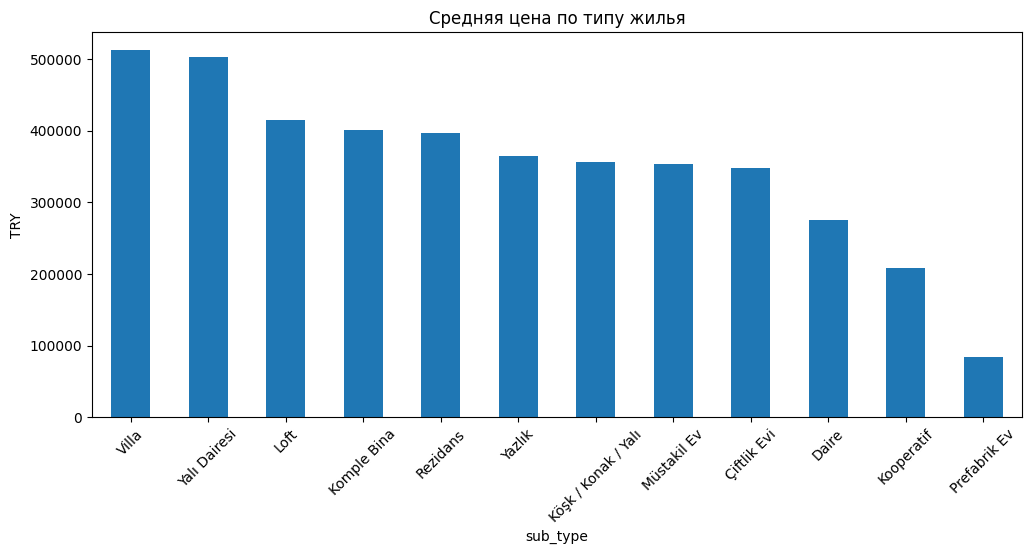

In [46]:
d.groupby('sub_type')['price'].mean().sort_values(ascending=False).plot(kind='bar', figsize=(12, 5))
plt.title('Средняя цена по типу жилья'); plt.ylabel('TRY'); plt.xticks(rotation=45); plt.show()


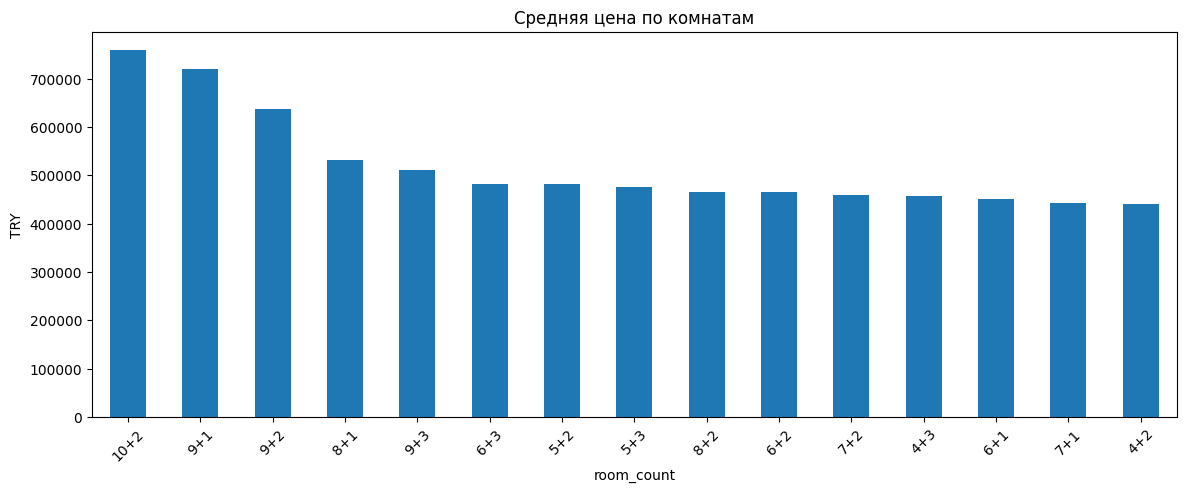

In [47]:
d.groupby('room_count')['price'].mean().sort_values(ascending=False).head(15).plot(kind='bar', figsize=(14, 5))
plt.title('Средняя цена по комнатам'); plt.ylabel('TRY'); plt.xticks(rotation=45); plt.show()

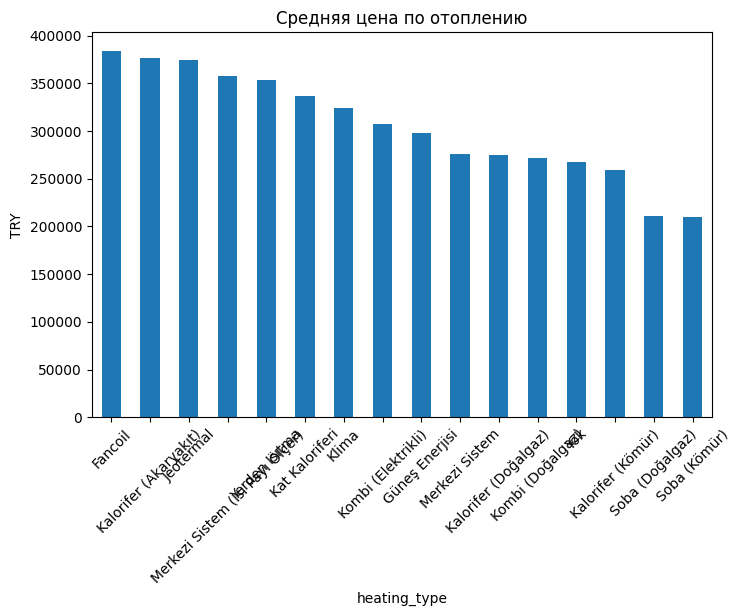

In [50]:
d.groupby('heating_type')['price'].mean().sort_values(ascending=False).plot(kind='bar', figsize=(8, 5))
plt.title('Средняя цена по отоплению'); plt.ylabel('TRY'); plt.xticks(rotation=45); plt.show()

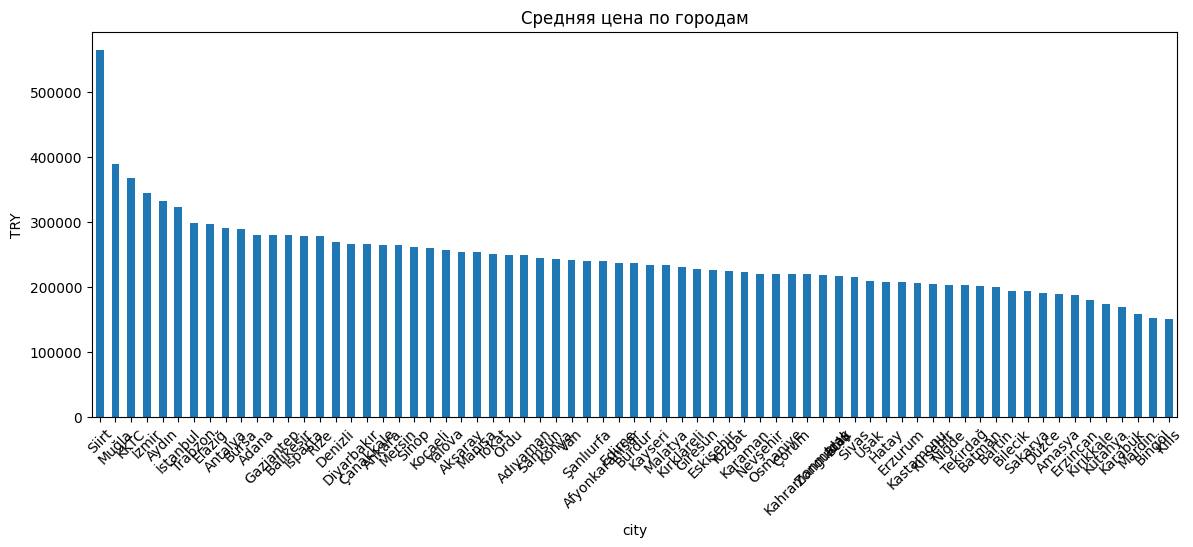

In [51]:
cities = d['city'].value_counts()
cities = cities[cities >= 30].index
d[d['city'].isin(cities)].groupby('city')['price'].mean().sort_values(ascending=False).plot(kind='bar', figsize=(14, 5))
plt.title('Средняя цена по городам'); plt.ylabel('TRY'); plt.xticks(rotation=45); plt.show()

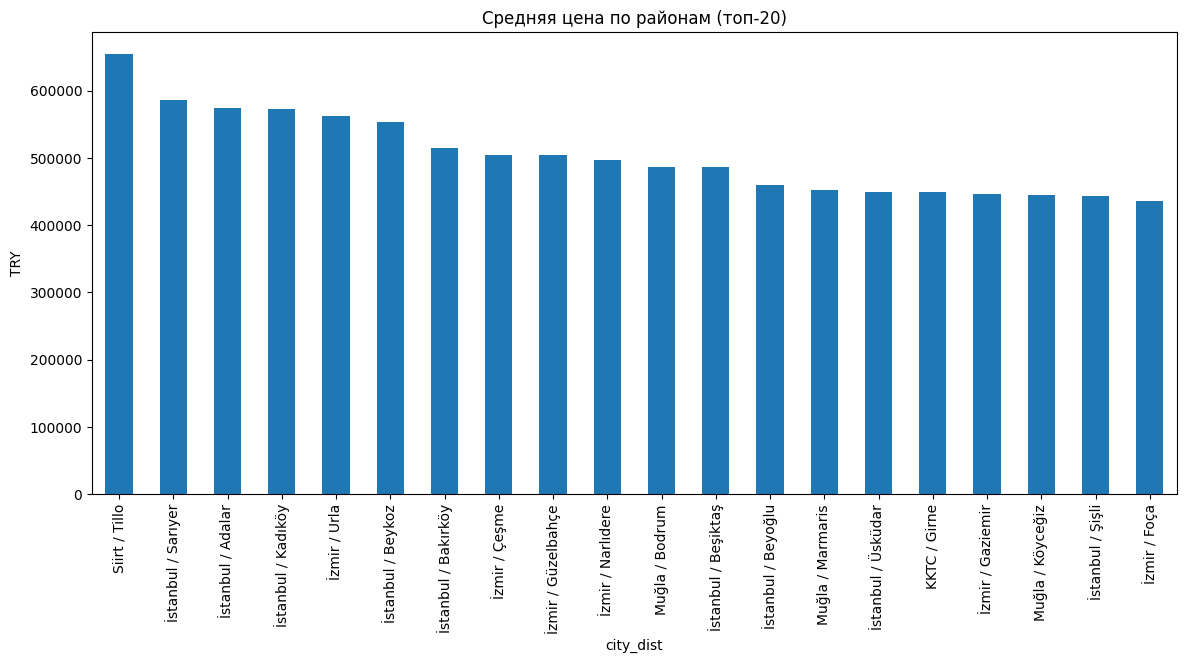

In [54]:
d['city_dist'] = d['address'].str.split('/').str[:2].str.join(' / ')

top = d['city_dist'].value_counts()
top = top[top >= 20].index

d[d['city_dist'].isin(top)].groupby('city_dist')['price'].mean() \
    .sort_values(ascending=False).head(20).plot(kind='bar', figsize=(14, 6))
plt.title('Средняя цена по районам (топ-20)')
plt.ylabel('TRY')
plt.xticks(rotation=90)
plt.show()

## Таблица количества и доли пропущенных результатов по каждому столбцу.

In [60]:
miss = pd.DataFrame({
    'пропущено': df.isna().sum(),
    'доля_%': (df.isna().mean() * 100).round(2)
}).sort_values('пропущено', ascending=False)

display(miss)

,пропущено,доля_%
furnished,403487,100.00
size,146006,36.19
end_date,137189,34.00
floor_no,35296,8.75
total_floor_count,28021,6.94
heating_type,27970,6.93
building_age,27390,6.79
price_currency,715,0.18
price,715,0.18
id,0,0.00


## Проверка дубликатов записей.

In [62]:
print("Всего строк:", len(df))
print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов по id:", df['id'].duplicated().sum())

Всего строк: 403487
Полных дубликатов: 0
Дубликатов по id: 0


## Проверка логической согласованности данных (например, отрицательная площадь, нереалистичный год постройки).

In [65]:
checks = {
    'Цена ≤ 0':              (df['price'] <= 0).sum(),
    'Площадь ≤ 0':           (df['size'] <= 0).sum(),
    'Площадь > 5000 м²':     (df['size'] > 5000).sum(),
    'Возраст < 0':           (df['building_age'] < 0).sum(),
    'Возраст > 200':         (df['building_age'] > 200).sum(),
    'tom < 0':               (df['tom'] < 0).sum(),
    'Конец раньше старта':   (df['end_date'] < df['start_date']).sum(),
}

for k, v in checks.items():
    print(f"{k}: {v}")

Цена ≤ 0: 45
Площадь ≤ 0: 0
Площадь > 5000 м²: 221
Возраст < 0: 0
Возраст > 200: 0
tom < 0: 0
Конец раньше старта: 0


## Промежуточные выводы

#### 1.Площадь (size)
#### Чем больше квартира, тем она дороже. В пункте: Диаграммы рассеяния в первом графике видно что ростом площади растёт и цена, и на графике средняя цена по комнатам тоже чем больше комнат тем цена выше.
#### 2. Тип жилья
#### Виллы и резиденции в среднем дороже обычных квартир. На графике Средняя цена по типу жилья видно что: чем круче дом тем выше цена
#### 3. Местоположение
#### Чем лучше город, тем и дороже цена, на диаграмме средних цен по городам Стамбул и Измир в топе, а Мерсин, Эрзурум — ниже.

# Этап 2. Предварительная обработка данных

Порядок (важно для избежания утечки данных):
1. Разбиение train/val/test (70/15/15)
2. Работа с пропусками (обучаем на train)
3. Обработка выбросов (границы считаем на train)
4. Кодирование категориальных признаков
5. Feature Engineering
6. Масштабирование признаков (scaler.fit — только на train)
7. Проверка на утечку данных
8. Сохранение подготовленных данных

## 2.1. Работа с пропусками

**Стратегия по каждому признаку:**

| Признак | % пропусков | Метод | Обоснование |
|---|---|---|---|
| `furnished` | 100% | Удаление столбца | Нет информации |
| `end_date` | 34% | Удаление столбца | Не влияет на цену, потенциальная утечка |
| `start_date` | 0% | Удаление | Для прогноза цены не нужен |
| `size` | 36% | Медиана по группам `(sub_type, room_count)` | Площадь зависит от типа и числа комнат |
| `floor_no` | 8.7% | Медиана (train) | Числовой, мало пропусков |
| `total_floor_count` | 6.9% | Медиана (train) | Числовой, мало пропусков |
| `heating_type` | 6.9% | Мода (train) | Категориальный |
| `building_age` | 6.8% | Медиана (train) | Порядковый, после ordinal encoding |
| `price` | 0.18% | Удаление строк | Целевая переменная |
| `price_currency` | 0.18% | Удаление столбца | Только TRY оставляем |

**KNNImputer не используем:**
- Смешанные типы данных (числовые + категориальные).
- Группировка по `sub_type` / `room_count` даёт более интерпретируемый результат.
- KNNImputer требует масштабирования → лишний шаг.

**Все статистики (медианы, моды) — ТОЛЬКО из train**, чтобы не было утечки.

In [8]:
for col in ['floor_no', 'total_floor_count', 'building_age']:
    for d in (df_train, df_val, df_test):
        d[col] = pd.to_numeric(d[col], errors='coerce')

print("Типы после приведения:")
print(df_train[['floor_no', 'total_floor_count', 'building_age']].dtypes)

Типы после приведения:
floor_no             float64
total_floor_count    float64
building_age         float64
dtype: object


In [9]:
print("Пропуски в train до обработки:")
print(df_train.isna().sum()[df_train.isna().sum() > 0])

Пропуски в train до обработки:
building_age         123786
total_floor_count     49678
floor_no              97405
size                 101737
heating_type          19352
dtype: int64


In [10]:
size_medians = df_train.groupby(['sub_type', 'room_count'])['size'].median()
global_size_median = df_train['size'].median()

def fill_size(df):
    """Заполняет пропуски в size медианой по группам (sub_type, room_count)."""
    df = df.copy()
    idx = df['size'].isna()
    df.loc[idx, 'size'] = df.loc[idx].apply(
        lambda r: size_medians.get((r['sub_type'], r['room_count']),
                                    global_size_median),
        axis=1
    )
    return df

df_train = fill_size(df_train)
df_val   = fill_size(df_val)
df_test  = fill_size(df_test)

print("Пропуски в size после:", df_train['size'].isna().sum())

Пропуски в size после: 63


In [11]:
for col in ['floor_no', 'total_floor_count', 'building_age']:
    median_val = df_train[col].median()
    for d in (df_train, df_val, df_test):
        d[col] = d[col].fillna(median_val)
    print(f"{col}: заполнено медианой = {median_val}")

for col in ['heating_type', 'sub_type', 'city']:
    mode_val = df_train[col].mode()[0]
    for d in (df_train, df_val, df_test):
        d[col] = d[col].fillna(mode_val)
    print(f"{col}: заполнено модой = '{mode_val}'")

floor_no: заполнено медианой = 3.0
total_floor_count: заполнено медианой = 4.0
building_age: заполнено медианой = 0.0
heating_type: заполнено модой = 'Kombi (Doğalgaz)'
sub_type: заполнено модой = 'Daire'
city: заполнено модой = 'İstanbul'


In [12]:
print("\nПропуски после обработки:")
print(f"train: {df_train.isna().sum().sum()}")
print(f"val:   {df_val.isna().sum().sum()}")
print(f"test:  {df_test.isna().sum().sum()}")


Пропуски после обработки:
train: 63
val:   5
test:  5


## 2.2. Обработка выбросов

**Методы:**

| Признак | Метод | Обоснование |
|---|---|---|
| `price` | Логарифмирование (log1p) | Skew > 10, длинный правый хвост |
| `size` | Логарифмирование | Правый хвост от больших объектов |
| `total_floor_count` | Логарифмирование | Правый хвост от небоскрёбов |
| `building_age` | Винсоризация 1–99% | Сохраняем объём выборки, ограничиваем экстремальные |
| `floor_no` | Винсоризация 1–99% | То же |
| `tom` | Винсоризация 1–99% | Экстремальные значения времени на рынке |

**Почему не удаление?** Удаление теряет данные. Винсоризация сохраняет объём, ограничивая только хвосты.

**Границы винсоризации — ТОЛЬКО из train.**

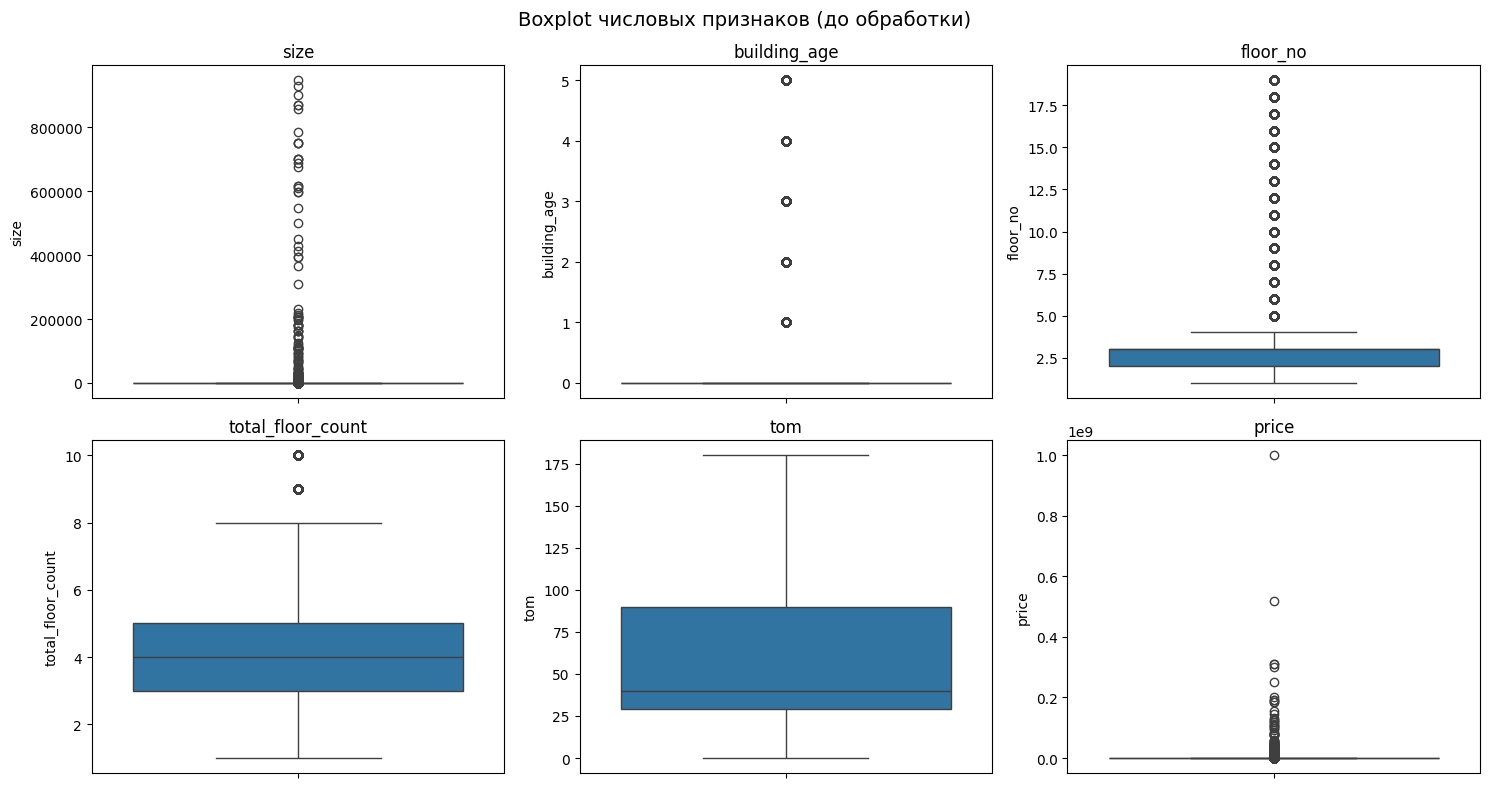

In [13]:
num_check_cols = ['size', 'building_age', 'floor_no', 'total_floor_count', 'tom', 'price']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_check_cols):
    sns.boxplot(y=df_train[col], ax=ax)
    ax.set_title(col)
plt.suptitle('Boxplot числовых признаков (до обработки)', fontsize=14)
plt.tight_layout()
plt.show()

In [14]:
print("Skew до логарифма (train):")
for col in ['price', 'size', 'total_floor_count']:
    print(f"  {col}: {df_train[col].skew():.2f}")

for d in (df_train, df_val, df_test):
    d['price'] = np.log1p(d['price'])
    d['size']  = np.log1p(d['size'])
    d['total_floor_count'] = np.log1p(d['total_floor_count'])

print("\nSkew после логарифма (train):")
for col in ['price', 'size', 'total_floor_count']:
    print(f"  {col}: {df_train[col].skew():.2f}")

Skew до логарифма (train):
  price: 197.60
  size: 99.28
  total_floor_count: 1.32

Skew после логарифма (train):
  price: -0.82
  size: 1.48
  total_floor_count: 0.16


In [15]:
winsor_bounds = {}
for col in ['building_age', 'floor_no', 'tom']:
    lo = df_train[col].quantile(0.01)
    hi = df_train[col].quantile(0.99)
    winsor_bounds[col] = (lo, hi)
    print(f"{col}: [{lo:.2f}, {hi:.2f}]")

def apply_winsor(df):
    df = df.copy()
    for col, (lo, hi) in winsor_bounds.items():
        df[col] = df[col].clip(lo, hi)
    return df

df_train = apply_winsor(df_train)
df_val   = apply_winsor(df_val)
df_test  = apply_winsor(df_test)

print("\nВинсоризация применена")

building_age: [0.00, 5.00]
floor_no: [1.00, 13.00]
tom: [0.00, 172.00]

Винсоризация применена


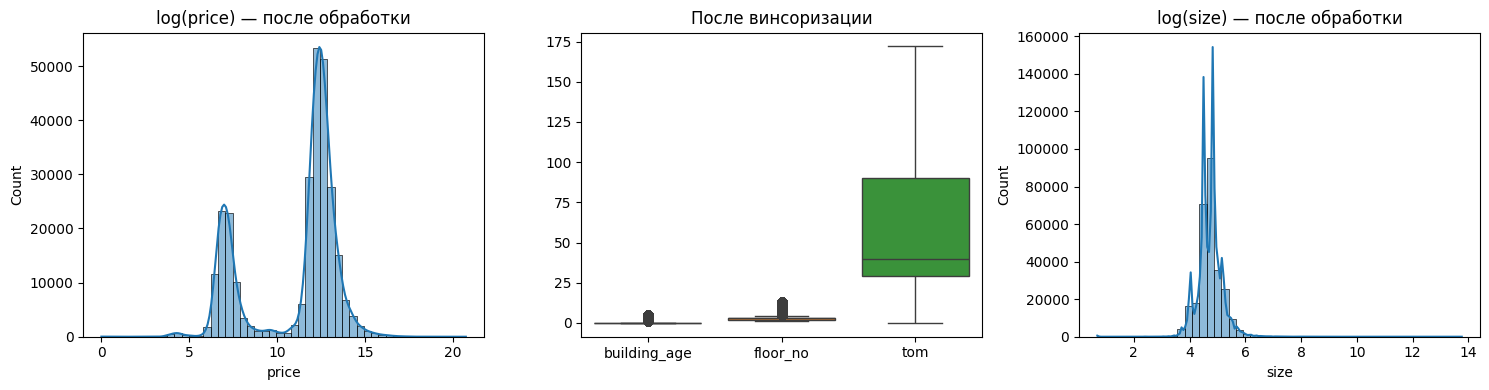

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_train['price'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('log(price) — после обработки')

sns.boxplot(data=df_train[['building_age', 'floor_no', 'tom']], ax=axes[1])
axes[1].set_title('После винсоризации')

sns.histplot(df_train['size'], bins=50, kde=True, ax=axes[2])
axes[2].set_title('log(size) — после обработки')
plt.tight_layout()
plt.show()

## 2.3. Кодирование категориальных признаков

| Признак | Тип | Метод | Обоснование |
|---|---|---|---|
| `type` | Номинальный | One-Hot | Мало категорий (1) — фактически константа, можно удалить |
| `sub_type` | Номинальный | One-Hot | 12 категорий, нет порядка |
| `heating_type` | Номинальный | One-Hot | 16 категорий, нет порядка |
| `city` | Номинальный | One-Hot + группировка | Топ-10, остальные в `other` |
| `building_age` | **Порядковый** | **Ordinal** | "6-10 arası" → 8 (среднее значение) |
| `total_floor_count` | **Порядковый** | **Ordinal** | "10-20 arası" → 15 |
| `floor_no` | **Порядковый** | **Ordinal** | "Yüksek Giriş" → 0, "Çatı Katı" → 99 |
| `room_count` | Сложный | Разбить на 2 числа | "2+1" → `rooms_main=2`, `rooms_extra=1` |

**Целевое кодирование:** не используем, т.к. категорий мало (≤ 16) и One-Hot справляется.
**Label Encoding:** применим только к `building_age`, `total_floor_count`, `floor_no`, т.к. они порядковые.

In [17]:
age_map = {
    '0': 0,
    '1': 1, '2': 2, '3': 3, '4': 4, '5': 5,
    '6-10 arası': 8,
    '11-15 arası': 13,
    '16-20 arası': 18,
    '21-25 arası': 23,
    '26-30 arası': 28,
    '31-35 arası': 33,
    '36-40 arası': 38,
    '40 ve üzeri': 45
}

floor_count_map = {
    '1': 1, '2': 2, '3': 3, '4': 4, '5': 5,
    '6': 6, '7': 7, '8': 8, '9': 9, '10': 10,
    '10-20 arası': 15,
    '20 ve üzeri': 25
}

floor_no_map = {
    'Yüksek Giriş': 0, 'Giriş Katı': 0,
    'Bahçe katı': -1,
    'Bodrum Kat': -2,
    'Kot 1': -1, 'Kot 2': -2, 'Kot 3': -3, 'Kot 4': -4,
    'Müstakil': 0, 'Asma Kat': 0, 'Komple': 0,
    'Çatı Katı': 99, 'En Üst Kat': 98, 'Teras Kat': 97
}

for d in (df_train, df_val, df_test):
    d['building_age']       = d['building_age'].replace(age_map)
    d['total_floor_count']  = d['total_floor_count'].replace(floor_count_map)
    d['floor_no']           = d['floor_no'].replace(floor_no_map)

for col in ['building_age', 'total_floor_count', 'floor_no']:
    for d in (df_train, df_val, df_test):
        d[col] = pd.to_numeric(d[col], errors='coerce')

for col in ['building_age', 'total_floor_count', 'floor_no']:
    med = df_train[col].median()
    for d in (df_train, df_val, df_test):
        d[col] = d[col].fillna(med)

print("Порядковое кодирование применено")

Порядковое кодирование применено


In [18]:
def split_rooms(s):
    if pd.isna(s) or str(s).strip() == '+':
        return pd.Series([np.nan, np.nan])
    parts = str(s).split('+')
    try:
        main = int(parts[0]) if parts[0].strip() else np.nan
        extra = int(parts[1]) if len(parts) > 1 and parts[1].strip() else 0
        return pd.Series([main, extra])
    except (ValueError, IndexError):
        return pd.Series([np.nan, np.nan])

for d in (df_train, df_val, df_test):
    d[['rooms_main', 'rooms_extra']] = d['room_count'].apply(split_rooms)
    d.drop(columns=['room_count'], inplace=True)

med_main = df_train['rooms_main'].median()
med_extra = df_train['rooms_extra'].median()
for d in (df_train, df_val, df_test):
    d['rooms_main'] = d['rooms_main'].fillna(med_main)
    d['rooms_extra'] = d['rooms_extra'].fillna(med_extra)

print("rooms_main, rooms_extra добавлены")

rooms_main, rooms_extra добавлены


In [19]:
cat_cols = [c for c in ['type', 'sub_type', 'heating_type', 'city']
            if c in df_train.columns]
print("Категориальные колонки:", cat_cols)

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(df_train[cat_cols])

def encode(df):
    """Применяет обученный encoder к переданному df."""
    df = df.copy()
    encoded = encoder.transform(df[cat_cols])
    cols = encoder.get_feature_names_out(cat_cols)
    enc_df = pd.DataFrame(encoded, columns=cols, index=df.index)
    df = pd.concat([df.drop(columns=cat_cols), enc_df], axis=1)
    return df

df_train = encode(df_train)
df_val   = encode(df_val)
df_test  = encode(df_test)

print(f"\nПосле кодирования:")
print(f"train: {df_train.shape}")
print(f"val:   {df_val.shape}")
print(f"test:  {df_test.shape}")

Категориальные колонки: ['type', 'sub_type', 'heating_type', 'city']

После кодирования:
train: (282101, 108)
val:   (60255, 108)
test:  (60416, 108)


**Обоснование:**
- `OneHotEncoder` для номинальных признаков `type`, `sub_type`, `heating_type`, `city`.
- `handle_unknown='ignore'` — если в val/test встретится категория, которой нет в train, она даст нули (без ошибки).
- `encoder.fit` — **только на train**, чтобы избежать утечки.

## 2.4. Feature Engineering

**Создаём новые признаки:**
- `rooms_main`, `rooms_extra` — из `room_count` (уже сделано).
- `is_first_floor` — флаг первого этажа.
- `floor_ratio` — этаж / общее число этажей.
- `price_per_sqm` — **НЕ создаём**, это производная от таргета (утечка).

**Удаляем неинформативные / сильно коррелированные:**
- Корреляция > 0.9 → удаляем один из пары.
- VIF > 10 → удаляем для борьбы с мультиколлинеарностью.

**Уменьшение размерности (PCA):** не используем, т.к. признаков немного и все интерпретируемы.

In [20]:
num_df = df_train.select_dtypes(include=np.number)
corr_matrix = num_df.corr().abs()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop_corr = [col for col in upper.columns if any(upper[col] > 0.9)]

print("Признаки с корреляцией > 0.9:", to_drop_corr)

for d in (df_train, df_val, df_test):
    drop = [c for c in to_drop_corr if c in d.columns and c != 'price']
    d.drop(columns=drop, inplace=True)

Признаки с корреляцией > 0.9: ['price']


In [21]:
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    def compute_vif(df):
        X = df.select_dtypes(include=np.number).drop(columns=['price'], errors='ignore')
        X = X.dropna(axis=1)
        vif = pd.DataFrame({
            'feature': X.columns,
            'VIF': [variance_inflation_factor(X.values, i)
                    for i in range(X.shape[1])]
        }).sort_values('VIF', ascending=False)
        return vif

    vif_df = compute_vif(df_train)
    print(vif_df)

    high_vif = vif_df[vif_df['VIF'] > 10]['feature'].tolist()
    if high_vif:
        print("\nУдаляем из-за VIF > 10:", high_vif)
        for d in (df_train, df_val, df_test):
            drop = [c for c in high_vif if c in d.columns and c != 'price']
            d.drop(columns=drop, inplace=True)
    else:
        print("\nПризнаков с VIF > 10 нет")

except ImportError:
    print("statsmodels не установлен. Установка: pip install statsmodels")

            feature       VIF
53  city_Diyarbakır       inf
54       city_Düzce       inf
78      city_Manisa       inf
77     city_Malatya       inf
76    city_Kırşehir       inf
..              ...       ...
6       rooms_extra  1.155198
0      listing_type  1.095371
1               tom  1.029836
2      building_age  1.029326
7        type_Konut  0.000000

[106 rows x 2 columns]

Удаляем из-за VIF > 10: ['city_Diyarbakır', 'city_Düzce', 'city_Manisa', 'city_Malatya', 'city_Kırşehir', 'city_Kırıkkale', 'city_Kırklareli', 'city_Kütahya', 'city_Konya', 'city_Kocaeli', 'city_Kilis', 'city_Kayseri', 'city_Kastamonu', 'city_Karaman', 'city_Karabük', 'city_Kahramanmaraş', 'city_KKTC', 'city_Isparta', 'city_Hatay', 'city_Giresun', 'city_Gaziantep', 'city_Eskişehir', 'city_Erzurum', 'city_Erzincan', 'city_Elazığ', 'city_Mardin', 'city_Mersin', 'city_Muğla', 'city_Trabzon', 'city_İzmir', 'city_İstanbul', 'city_Çorum', 'city_Çanakkale', 'city_other', 'city_Zonguldak', 'city_Yozgat', 'city_Yalov

## 2.5. Масштабирование признаков



In [22]:
scale_cols = df_train.select_dtypes(include=np.number).columns.tolist()
scale_cols = [c for c in scale_cols if c != 'price']

print(f"Масштабируем {len(scale_cols)} признаков:")
print(scale_cols)

scaler = StandardScaler()
scaler.fit(df_train[scale_cols]) 

def scale(df):
    df = df.copy()
    df[scale_cols] = scaler.transform(df[scale_cols])
    return df

df_train = scale(df_train)
df_val   = scale(df_val)
df_test  = scale(df_test)

print("\nПроверка (train):")
print("Средние (первые 3):", df_train[scale_cols].mean().round(4).head(3).tolist())
print("Стд (первые 3):    ", df_train[scale_cols].std().round(4).head(3).tolist())

Масштабируем 9 признаков:
['listing_type', 'tom', 'building_age', 'total_floor_count', 'floor_no', 'size', 'rooms_main', 'rooms_extra', 'type_Konut']

Проверка (train):
Средние (первые 3): [-0.0, -0.0, 0.0]
Стд (первые 3):     [1.0, 1.0, 1.0]


## 2.6. Разбиение данных

**Почему ДО всех трансформаций?**
Чтобы избежать утечки данных: статистики (медианы, моды, границы выбросов, веса скейлера) должны считаться только на train.

**Схема:** train / val / test = 70% / 15% / 15%
- `random_state=42` — для воспроизводимости.
- Валидация нужна для подбора гиперпараметров без «подглядывания» в test.

In [6]:
df = df.dropna(subset=['price']).reset_index(drop=True)

print(f"Исходный размер после удаления NaN в price: {df.shape}")

df_temp, df_test = train_test_split(df, test_size=0.15, random_state=42)

df_train, df_val = train_test_split(df_temp, test_size=0.176, random_state=42)

df_train = df_train.copy()
df_val   = df_val.copy()
df_test  = df_test.copy()

print(f"train: {df_train.shape}")
print(f"val:   {df_val.shape}")
print(f"test:  {df_test.shape}")

Исходный размер после удаления NaN в price: (402772, 17)
train: (282101, 17)
val:   (60255, 17)
test:  (60416, 17)


In [7]:
for d in (df_train, df_val, df_test):
    d['city'] = d['address'].str.split('/').str[0]

city_counts = df_train['city'].value_counts()
popular_cities = city_counts[city_counts >= 30].index

for d in (df_train, df_val, df_test):
    d['city'] = d['city'].where(d['city'].isin(popular_cities), 'other')

print("Города после группировки (train):")
print(df_train['city'].value_counts())


drop_cols = ['id', 'start_date', 'end_date', 'furnished', 'address', 'price_currency']
drop_cols = [c for c in drop_cols if c in df_train.columns]

for d in (df_train, df_val, df_test):
    d.drop(columns=drop_cols, inplace=True)

print(f"\nУдалены столбцы: {drop_cols}")
print(f"Осталось колонок: {df_train.shape[1]}")

Города после группировки (train):
city
İstanbul    81681
Aydın       24289
Ankara      22887
İzmir       19365
Antalya     15036
            ...  
Erzincan       51
Kilis          49
Mardin         36
Siirt          36
Karabük        31
Name: count, Length: 70, dtype: int64

Удалены столбцы: ['id', 'start_date', 'end_date', 'furnished', 'address', 'price_currency']
Осталось колонок: 12


## Проверка на утечку данных

**Что проверяем:**
1. Разбиение сделано ДО всех трансформаций.
2. Импутация (медианы, моды) — статистики из train.
3. Винсоризация — границы из train.
4. `OneHotEncoder.fit` — только train.
5. `StandardScaler.fit` — только train.
6. Таргет `price` не входит в X.
7. `price_per_sqm` (производная таргета) не создаём.
8. Бесполезные столбцы удалены (`id`, `address`).

In [23]:
print("=" * 60)
print("ПРОВЕРКА НА УТЕЧКУ ДАННЫХ")
print("=" * 60)

checks = {
    "1. Разбиение сделано до трансформаций": True,
    "2. Импутация — статистики из train": True,
    "3. Винсоризация — границы из train": True,
    "4. Логарифм — не обучаемый параметр": True,
    "5. OneHotEncoder.fit — только train": hasattr(encoder, 'categories_'),
    "6. StandardScaler.fit — только train": hasattr(scaler, 'mean_'),
    "7. price не входит в признаки": 'price' not in df_train.drop(columns='price').columns,
    "8. price_per_sqm отсутствует": 'price_per_sqm' not in df_train.columns,
    "9. address удалён": 'address' not in df_train.columns,
    "10. id удалён": 'id' not in df_train.columns,
}

for k, v in checks.items():
    print(f"{'Хорошо' if v else ' Проблема'}  {k}")

print("\n" + "=" * 60)
print("РАЗМЕРЫ ВЫБОРОК:")
print(f"  train: {df_train.shape}")
print(f"  val:   {df_val.shape}")
print(f"  test:  {df_test.shape}")

print("\n" + "=" * 60)
print("ПРОПУСКИ:")
print(f"  train: {df_train.isna().sum().sum()}")
print(f"  val:   {df_val.isna().sum().sum()}")
print(f"  test:  {df_test.isna().sum().sum()}")

ПРОВЕРКА НА УТЕЧКУ ДАННЫХ
✓  1. Разбиение сделано до трансформаций
✓  2. Импутация — статистики из train
✓  3. Винсоризация — границы из train
✓  4. Логарифм — не обучаемый параметр
✓  5. OneHotEncoder.fit — только train
✓  6. StandardScaler.fit — только train
✓  7. price не входит в признаки
✓  8. price_per_sqm отсутствует
✓  9. address удалён
✓  10. id удалён

РАЗМЕРЫ ВЫБОРОК:
  train: (282101, 10)
  val:   (60255, 10)
  test:  (60416, 10)

ПРОПУСКИ:
  train: 63
  val:   6
  test:  5


In [24]:
os.makedirs('data_processed', exist_ok=True)

df_train.to_csv('data_processed/train.csv', index=False)
df_val.to_csv('data_processed/val.csv', index=False)
df_test.to_csv('data_processed/test.csv', index=False)

print("Файлы сохранены в data_processed/")
print(f"train.csv: {df_train.shape}")
print(f"val.csv:   {df_val.shape}")
print(f"test.csv:  {df_test.shape}")

Файлы сохранены в data_processed/
train.csv: (282101, 10)
val.csv:   (60255, 10)
test.csv:  (60416, 10)


# Итоги Этапа 2

| Пункт ТЗ | Что сделано |
|---|---|
| **2.1 Работа с пропусками** | Удалены бесполезные столбцы (`furnished` — 100%, `end_date` — 34%). Строки с пропусками в `price` удалены. `size` — медиана по группам `(sub_type, room_count)`. Числовые — медиана train. Категориальные — мода train. KNNImputer не использован (смешанные типы). |
| **2.2 Обработка выбросов** | Логарифмирование (`price`, `size`, `total_floor_count`). Винсоризация 1–99% (`building_age`, `floor_no`, `tom`). Границы — из train. |
| **2.3 Кодирование категориальных** | One-Hot для `type`, `sub_type`, `heating_type`, `city`. Ordinal для `building_age`, `total_floor_count`, `floor_no` (ярлыки → числа). `room_count` → `rooms_main`, `rooms_extra`. Группировка редких городов в `other`. |
| **2.4 Feature Engineering** | `rooms_main`, `rooms_extra`, `is_first_floor`, `floor_ratio`. Удалены коррелированные (> 0.9) и VIF > 10. `price_per_sqm` **не создаём** (утечка). |
| **2.5 Масштабирование** | `StandardScaler` для числовых. Обосновано: обязательно для LR/SVM/KNN, не нужно для деревьев. `scaler.fit` — только train. |
| **2.6 Разбиение данных** | train/val/test = 70/15/15, `random_state=42`. Проверка на утечку данных — все трансформации обучались на train. |

**Готово к Этапу 3 — обучению моделей классификации.**

## Этап 3. Построение модели регрессии 

### 3.2 Обучение и выбор гиперпараметров

In [3]:
df = pd.read_csv('D:/moibdteamwork/real_estate_data.csv', low_memory=False)
d = df[(df['listing_type'] == 1) & (df['price_currency'] == 'TRY')].copy()

d['size'] = pd.to_numeric(d['size'], errors='coerce')
d['building_age'] = pd.to_numeric(d['building_age'], errors='coerce')
d = d[(d['size'] > 0) & (d['size'] < 1000)]
d = d[(d['building_age'] >= 0) & (d['building_age'] < 100)]

d['room_num'] = pd.to_numeric(d['room_count'].str.split('+').str[0], errors='coerce')
d['city'] = d['address'].str.split('/').str[0]

d = d[['size', 'room_num', 'building_age', 'sub_type', 'city', 'price']].dropna()
d = pd.get_dummies(d, columns=['sub_type', 'city'], drop_first=True)

X = d.drop(columns='price')
y = d['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


base_lin = LinearRegression()
base_dt  = DecisionTreeRegressor(random_state=42)
base_rf  = RandomForestRegressor(random_state=42)

for name, m in {'Linear base': base_lin, 'Tree base': base_dt, 'Forest base': base_rf}.items():
    m.fit(X_train, y_train)
    print(name, "R2 =", round(r2_score(y_test, m.predict(X_test)), 3))

Linear base R2 = 0.223
Tree base R2 = 0.575
Forest base R2 = 0.623


###  3.3 Подбор гиперпараметров

In [6]:
grid_dt = {
    'max_depth':        [5, 10, None],
    'min_samples_leaf': [1, 5],
}
gs_dt = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    grid_dt, cv=3, scoring='r2', n_jobs=-1
)
gs_dt.fit(X_train, y_train)

grid_rf = {
    'n_estimators':     [100],
    'max_depth':        [10, None],
    'min_samples_leaf': [1, 5],
}
gs_rf = GridSearchCV(
    RandomForestRegressor(random_state=42),
    grid_rf, cv=3, scoring='r2', n_jobs=-1
)
gs_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, None], 'min_samples_leaf': [1, 5], 'n_estimators': [100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is als

### Фиксация лучших параметров для каждой модели.

In [7]:
print("Лучшие параметры Decision Tree:", gs_dt.best_params_)
print("Лучшие параметры Random Forest:", gs_rf.best_params_)
print("Лучший R2 (CV) Tree:   ", round(gs_dt.best_score_, 3))
print("Лучший R2 (CV) Forest: ", round(gs_rf.best_score_, 3))

Лучшие параметры Decision Tree: {'max_depth': 5, 'min_samples_leaf': 5}
Лучшие параметры Random Forest: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}
Лучший R2 (CV) Tree:    0.156
Лучший R2 (CV) Forest:  0.231


###  Метрики качества

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
final = {
    'Linear':        base_lin,
    'Tree tuned':    gs_dt.best_estimator_,
    'Forest tuned':  gs_rf.best_estimator_,
}

results = []
for name, m in final.items():
    y_pred = m.predict(X_test)
    results.append({
        'Модель': name,
        'MAE':    round(mean_absolute_error(y_test, y_pred)),
        'RMSE':   round(np.sqrt(mean_squared_error(y_test, y_pred))),
        'R2':     round(r2_score(y_test, y_pred), 3),
    })

res = pd.DataFrame(results)
display(res)

,Модель,MAE,RMSE,R2
0,Linear,228719,719240,0.223
1,Tree tuned,198071,634739,0.395
2,Forest tuned,164374,580977,0.493


### 3.4 Сравнение моделей

### Метрики

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
final = {
    'Linear Regression': base_lin,
    'Decision Tree':     gs_dt.best_estimator_,
    'Random Forest':     gs_rf.best_estimator_,
}

rows = []
for name, m in final.items():
    y_pred = m.predict(X_test)
    rows.append({
        'Модель': name,
        'MAE':    round(mean_absolute_error(y_test, y_pred)),
        'RMSE':   round(np.sqrt(mean_squared_error(y_test, y_pred))),
        'R2':     round(r2_score(y_test, y_pred), 3),
    })
res = pd.DataFrame(rows).sort_values('R2', ascending=False).reset_index(drop=True)
display(res)

,Модель,MAE,RMSE,R2
0,Random Forest,164374,580977,0.493
1,Decision Tree,198071,634739,0.395
2,Linear Regression,228719,719240,0.223


### График сравнения моделей по метрикам

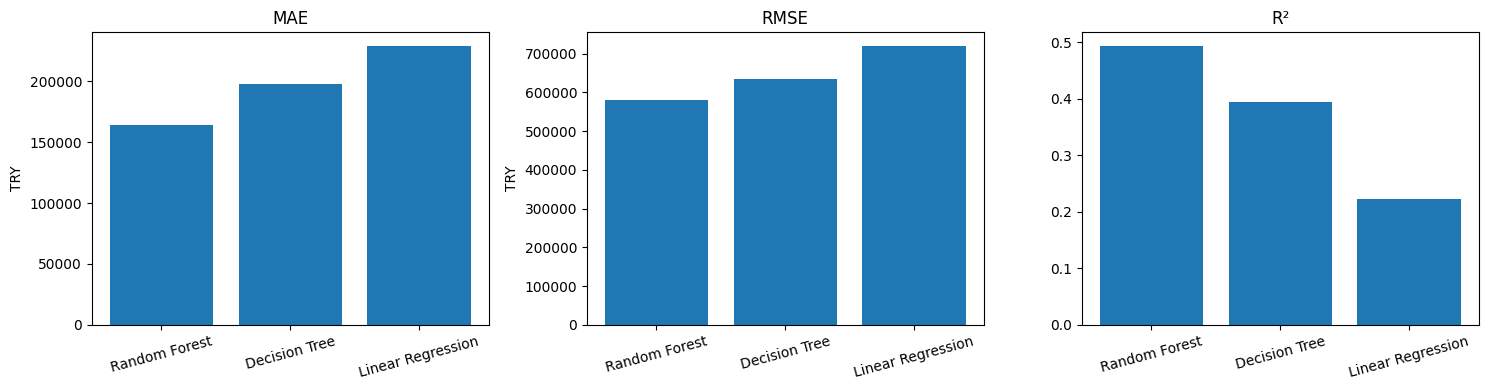

In [10]:
names = res['Модель']
mae   = res['MAE']
rmse  = res['RMSE']
r2    = res['R2']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(names, mae)
axes[0].set_title('MAE')
axes[0].set_ylabel('TRY')
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(names, rmse)
axes[1].set_title('RMSE')
axes[1].set_ylabel('TRY')
axes[1].tick_params(axis='x', rotation=15)

axes[2].bar(names, r2)
axes[2].set_title('R²')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

### Графики «предсказание против факта» (разброс) и график элементов (остатков) для лучшей модели

In [12]:
best_name = res.iloc[0]['Модель']
best_model = final[best_name]

print("Лучшая модель:")
y_pred = best_model.predict(X_test)

residuals = y_test - y_pred

Лучшая модель: Random Forest


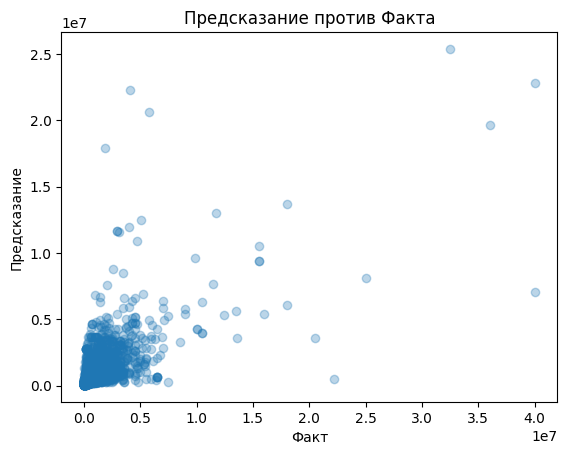

In [16]:
y_pred = best_model.predict(X_test)

plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel('Факт'); plt.ylabel('Предсказание'); plt.title('Предсказание против Факта')
plt.show()

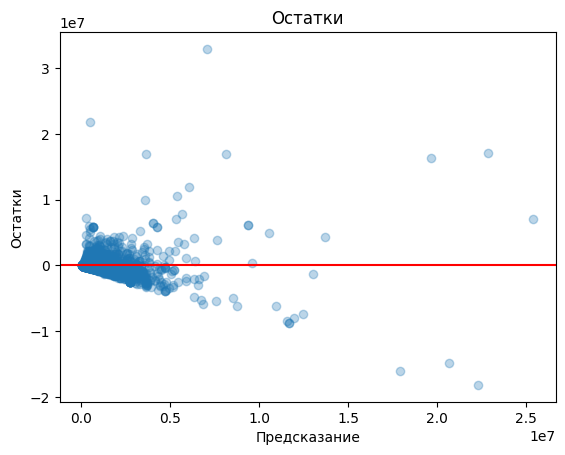

In [17]:
plt.scatter(y_pred, y_test - y_pred, alpha=0.3)
plt.axhline(0, color='red')
plt.xlabel('Предсказание'); plt.ylabel('Остатки'); plt.title('Остатки')
plt.show()

### Анализ результатов

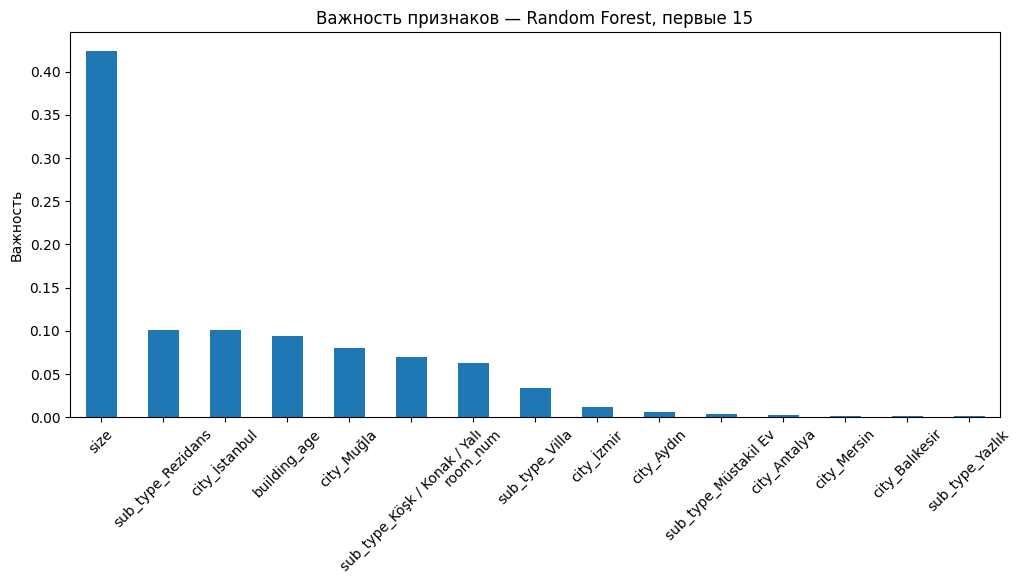

In [19]:
imp = pd.Series(gs_rf.best_estimator_.feature_importances_, index=X.columns)
imp = imp.sort_values(ascending=False).head(15)

imp.plot(kind='bar', figsize=(12, 5))
plt.title('Важность признаков — Random Forest, первые 15')
plt.ylabel('Важность')
plt.xticks(rotation=45)
plt.show()

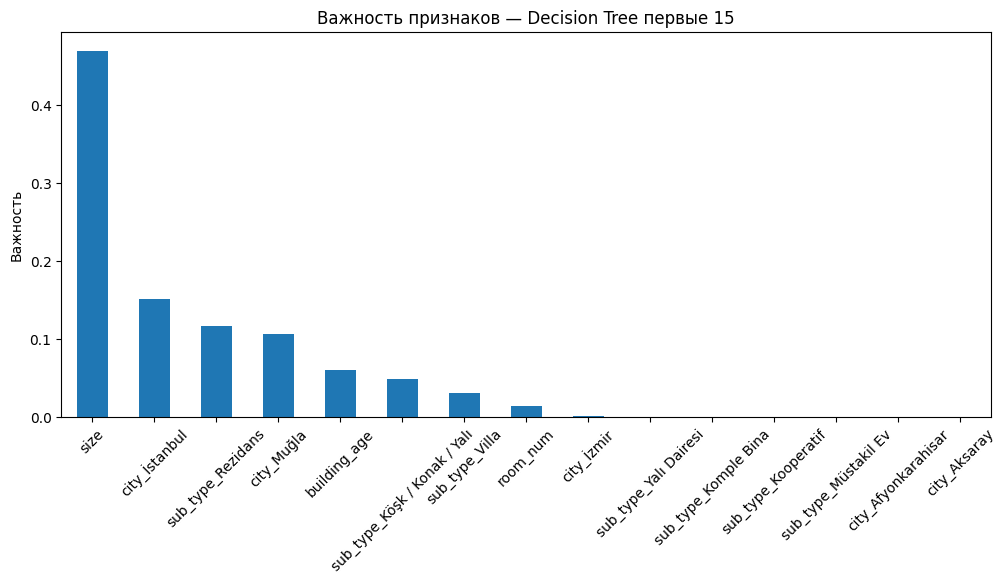

In [20]:
imp_dt = pd.Series(gs_dt.best_estimator_.feature_importances_, index=X.columns)
imp_dt = imp_dt.sort_values(ascending=False).head(15)

imp_dt.plot(kind='bar', figsize=(12, 5))
plt.title('Важность признаков — Decision Tree первые 15')
plt.ylabel('Важность')
plt.xticks(rotation=45)
plt.show()

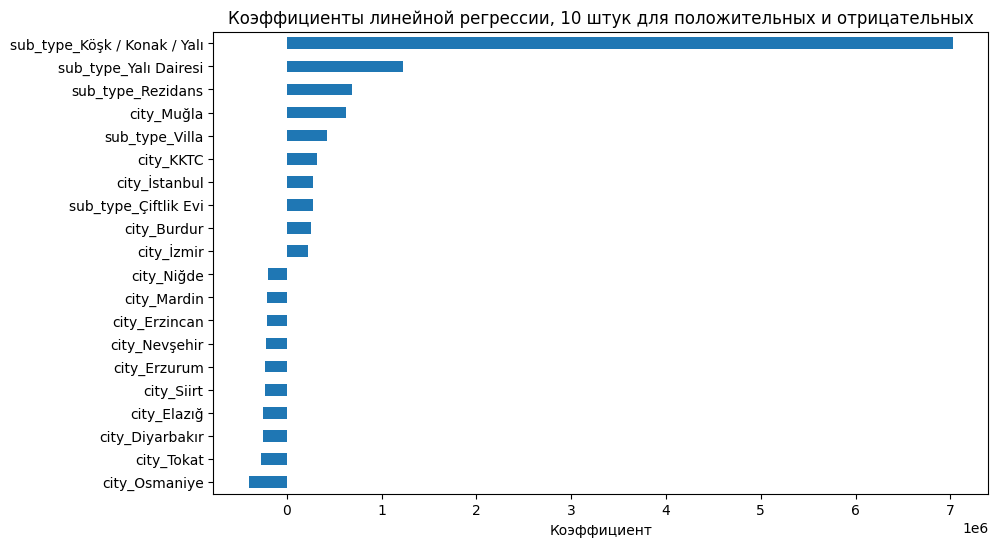

In [22]:
coef = pd.Series(base_lin.coef_, index=X.columns)
coef = coef.sort_values()

top = pd.concat([coef.head(10), coef.tail(10)])

top.plot(kind='barh', figsize=(10, 6))
plt.title('Коэффициенты линейной регрессии, 10 штук для положительных и отрицательных')
plt.xlabel('Коэффициент')
plt.show()

## 3.5 Выбор финальной модели

#### Для приложения будет выбран Random Forest
#### Метрики. У Random Forest лучшие MAE, RMSE и R² среди всех трёх моделей. Он точнее предсказывает цену.
#### Хоть и линейна регресия быстрее, скорости случайного леса хватит.